# Day 3 - Exploring Mumbai Rental Profiles
Group 3: Ahmed Belahcen, Nandini Rathod, Sanjana Kiran, Akanksha Dhumal.
AI Methods I, IAAC MaAI 2026/27.



### Load the existing cleaned snapshot
One row is an advertised property listing. It may not represent a unique dwelling. This CSV is reused from Day 2 without changing it. Inspecting data does not mean the data is already suitable for clustering.



In [11]:
from pathlib import Path
import pandas as pd

# Support running from notebook/ or the project root in VS Code.
project_dir = Path.cwd()
if not (project_dir / "data/mumbai_cleaned.csv").exists():
    project_dir = project_dir.parent

data_path = project_dir / "data/mumbai_cleaned.csv"
df = pd.read_csv(data_path)
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (18846, 26)


,Title,Price,Area,BHK,Bathrooms,Furnished,Balconies,Floor,Ownership,Facing,...,Description,Property Image,Price_per_m2,Suspicious_Price,Price_num,Area_num,BHK_num,Bathrooms_num,Balconies_num,Furnished_clean
0,1BHK Multistorey Apartment for Rent in Bandra ...,70000.0,750.0,1.0,1.0,Furnished,NaN,7.0,Unknown,South -West,...,"1 BHK, Multistorey Apartment is available for ...",67249079_2_PropertyImage345-4855396928822.jpg,93.333333,False,70000.0,750.0,1.0,1.0,NaN,Furnished
1,3BHK Multistorey Apartment for Rent in Lodha N...,140000.0,1980.0,3.0,4.0,Unfurnished,4.0,21.0,Unknown,East,...,"3 BHK, Multistorey Apartment is available for ...",66155783_5_hatsAppImage20230217at13.56.28.jpeg,70.707071,False,140000.0,1980.0,3.0,4.0,4.0,Unfurnished
2,3BHK Multistorey Apartment for Rent in Lodha P...,190000.0,1592.0,3.0,3.0,Unfurnished,1.0,20.0,Unknown,North - East,...,"3 BHK, Multistorey Apartment is available for ...",66686709_1_HOTO20230407165614.jpg,119.346734,False,190000.0,1592.0,3.0,3.0,1.0,Unfurnished
3,3BHK Multistorey Apartment for Rent in Rustomj...,110000.0,1305.0,3.0,3.0,Unfurnished,3.0,11.0,Freehold,West,...,"3 BHK, Multistorey Apartment is available for ...",67875387_1_PropertyImage559-8385323621333.jpg,84.291188,False,110000.0,1305.0,3.0,3.0,3.0,Unfurnished
4,3BHK Multistorey Apartment for Rent in DLH The...,140000.0,1350.0,3.0,3.0,Unfurnished,NaN,29.0,Freehold,East,...,"3 BHK, Multistorey Apartment is available for ...",66670931_3_PropertyImage314-6685675359874.jpg,103.703704,False,140000.0,1350.0,3.0,3.0,NaN,Unfurnished


### What information is available?

We look at names and data types before selecting any feature. Several `_num` columns duplicate original numeric fields. We should not include both copies: that would give the same property characteristic extra weight.

In [12]:
df.dtypes.to_frame("Data type")

,Data type
Title,str
Price,float64
Area,float64
BHK,float64
Bathrooms,float64
Furnished,str
Balconies,float64
Floor,float64
Ownership,str
Facing,str


### Where is information missing?

Missing does not automatically mean zero. In particular, an unknown balcony count is not evidence that a dwelling has no balcony. We will choose an imputation approach after discussing the consequences.


In [13]:
missing = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing percent": 100 * df.isna().mean(),
})
missing.sort_values("Missing percent", ascending=False).round(2)


,Missing values,Missing percent
Balconies,10323,54.78
Balconies_num,10323,54.78
Year of Construction,5229,27.75
Property Image,2297,12.19
Floor,737,3.91
Bathrooms,15,0.08
Bathrooms_num,15,0.08
Furnished,13,0.07
Furnished_clean,13,0.07
Price,0,0.00


### Check the city column and repeated feature/price records

The previous audit found that `Location` is a constant city label. we recheck this rather than assuming it describes neighborhoods. Repeated combinations of characteristics and rent are not proof of duplicate dwellings, but they can give some profiles extra weight. 

In [14]:
print("Location values:")
print(df["Location"].value_counts(dropna=False))

check_columns = [
    "Area_num", "BHK_num", "Bathrooms_num", "Balconies_num",
    "Furnished_clean", "Facing", "Location", "Property Type", "Price_num",
]
print("Repeated feature/price rows:", df.duplicated(subset=check_columns).sum())


Location values:
Location
Mumbai    18846
Name: count, dtype: int64
Repeated feature/price rows: 2487


## Step 1 — Define similarity and prepare the features

Our question is: **do listings with similar area, bedroom count and bathroom count form interpretable profiles?** No cluster has been fitted yet, and we do not assume that distinct groups necessarily exist.

| Column | Role in this first pass | Reason |
|---|---|---|
| `Area_num` | Clustering feature | Reported floor area is an important physical attribute; source declares ft² |
| `BHK_num` | Clustering feature | Bedroom count describes layout/capacity |
| `Bathrooms_num` | Clustering feature | Bathroom count adds information about facilities |
| `Price_num` | Interpretation only | We want to examine rents after grouping, rather than define groups by price |
| `Furnished_clean` | Interpretation only | We want to examine furnishing after grouping |
| `Facing`, `Property Type` | Interpretation only | Useful context to compare after clustering |
| `Balconies_num` | Excluded from this first feature set | More than half the values are missing; imputation could dominate its apparent pattern |
| `Location` | Context only | It is a constant city label, not a neighborhood feature |
| Original numeric columns | Excluded as duplicate features | Do not count both `Area` and `Area_num`, for example |
| Price-derived fields, title, description and image | Excluded from clustering | Outside the physical-profile question; text/images are not required |

Keeping rent aside avoids a circular claim such as discovering expensive groups after using rent to define them. Including rent would be a different, potentially valid market-segmentation question; the team should decide which question it wants.

Area, bedrooms and bathrooms are correlated. Scaling does not remove this redundancy; the next PCA step will help us inspect it. We are not interpreting the three features as independent causes.

In [15]:
# These lists make the proposed roles explicit and easy to change together.
cluster_features = ["Area_num", "BHK_num", "Bathrooms_num"]
interpretation_features = [
    "Price_num", "Furnished_clean", "Facing", "Property Type",
]

assert set(cluster_features).isdisjoint(interpretation_features)
assert all(column in df.columns for column in cluster_features + interpretation_features)

feature_audit = pd.DataFrame({
    "Missing": df[cluster_features].isna().sum(),
    "Minimum": df[cluster_features].min(),
    "Median": df[cluster_features].median(),
    "Maximum": df[cluster_features].max(),
    "Skewness": df[cluster_features].skew(),
})
display(feature_audit.round(3))

,Missing,Minimum,Median,Maximum,Skewness
Area_num,0,250.0,1100.0,14500.0,3.000
BHK_num,0,1.0,2.0,5.0,0.424
Bathrooms_num,15,1.0,2.0,6.0,0.975


### Keep the source intact and make eligibility rules visible

We will work on a copy. We need positive area and a positive bedroom count. A missing bathroom count can be imputed, but a non-missing non-positive bathroom count would require review. Values are already numeric in the cleaned CSV; we will still be checking for non-finite values.

We do not directly remove repeated rows, luxury properties or rare profiles. Repeated characteristics do not prove the same dwelling. Their possible extra weight will need a sensitivity check before final conclusions. These rules do not claim that the original cleaning or units are perfect.

`source_row` is a local row-position identifier for tracing labels back to this exact CSV. It is **not** a property ID and must not be used as a clustering feature.

In [16]:
import numpy as np

working_data = df.copy()
working_data.insert(0, "source_row", np.arange(len(working_data)))

valid_area = np.isfinite(working_data["Area_num"]) & (working_data["Area_num"] > 0)
valid_bhk = np.isfinite(working_data["BHK_num"]) & (working_data["BHK_num"] > 0)
bathrooms = working_data["Bathrooms_num"]
valid_bathrooms = bathrooms.isna() | (np.isfinite(bathrooms) & (bathrooms > 0))
eligible = valid_area & valid_bhk & valid_bathrooms

analysis_data = working_data.loc[eligible].copy()
X_cluster = analysis_data[cluster_features].copy()

print("Source rows:", len(df))
print("Eligible rows:", len(analysis_data))
print("Rows set aside for review:", int((~eligible).sum()))
print("Missing bathroom counts to impute:", int(X_cluster["Bathrooms_num"].isna().sum()))
print("Distinct physical feature combinations:", len(X_cluster.drop_duplicates()))
print("Repeated physical combinations retained:", int(X_cluster.duplicated().sum()))
print("These are repeated profiles, not verified duplicate dwellings.")
assert analysis_data["source_row"].is_unique
assert len(analysis_data) > 0


Source rows: 18846
Eligible rows: 18846
Rows set aside for review: 0
Missing bathroom counts to impute: 15
Distinct physical feature combinations: 2478
Repeated physical combinations retained: 16368
These are repeated profiles, not verified duplicate dwellings.


### Transform area, impute missing values and scale

**Area:** first inspect its skewness. We propose `log1p(area)`, meaning `ln(1 + area)`, to reduce the influence of very large areas on distances without deleting them. This is a modeling choice and does not repair incorrect units. It means proportional differences in area receive more emphasis than absolute differences.

**Bedrooms and bathrooms:** keep counts on their original scale before standardization; their order and differences have physical meaning.

**Missing values:** fill missing numeric values with the median fitted on this analysis sample. In this snapshot this primarily affects bathrooms. Imputation is an assumption, not recovered information.

**Scaling:** `StandardScaler` centers each transformed feature and divides it by its standard deviation. Otherwise, area measured in hundreds or thousands would dominate counts measured in single digits. Standardization gives comparable marginal scales; it does not make every feature equally informative.

All learned transformations belong in one `Pipeline`, as required by the course. There is no supervised train/test split at this exploratory stage: the preprocessing is fitted on the eligible analysis sample. Later stability runs must refit preprocessing within each subsample. We will not use t-SNE coordinates as the clustering inputs.


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

area_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log_area", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
])

count_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

feature_steps = ColumnTransformer([
    ("area", area_steps, ["Area_num"]),
    ("counts", count_steps, ["BHK_num", "Bathrooms_num"]),
], remainder="drop")

preprocessing = Pipeline([
    ("features", feature_steps),
    ("scale", StandardScaler()),
])

X_scaled = preprocessing.fit_transform(X_cluster)
scaled_features = pd.DataFrame(
    X_scaled,
    columns=["log_area_scaled", "bhk_scaled", "bathrooms_scaled"],
    index=analysis_data.index,
)

print("Prepared matrix shape:", scaled_features.shape)
print("Skewness before area log transform:", round(X_cluster["Area_num"].skew(), 3))
print("Skewness after area log transform:", round(np.log1p(X_cluster["Area_num"]).skew(), 3))
display(scaled_features.head().round(3))
display(pd.DataFrame({
    "Mean": X_scaled.mean(axis=0),
    "Population std": X_scaled.std(axis=0),
}, index=scaled_features.columns).round(6))

assert X_scaled.shape == (len(analysis_data), len(cluster_features))
assert np.isfinite(X_scaled).all()

Prepared matrix shape: (18846, 3)
Skewness before area log transform: 3.0
Skewness after area log transform: 0.252


,log_area_scaled,bhk_scaled,bathrooms_scaled
0,-0.754,-1.355,-1.471
1,1.145,0.841,1.797
2,0.718,0.841,0.708
3,0.329,0.841,0.708
4,0.396,0.841,0.708


,Mean,Population std
log_area_scaled,-0.0,1.0
bhk_scaled,-0.0,1.0
bathrooms_scaled,0.0,1.0


### Check that the pipeline also handles a hand-made input

This is only a preprocessing check, **not a cluster prediction**. The pipeline transforms new data with the fitted medians and scaling parameters; it must not refit them on each new example.

In [18]:
example_property = pd.DataFrame([{
    "Area_num": 750.0,
    "BHK_num": 2.0,
    "Bathrooms_num": np.nan,
}])
example_scaled = preprocessing.transform(example_property)
assert example_scaled.shape == (1, 3)
assert np.isfinite(example_scaled).all()
display(pd.DataFrame(example_scaled, columns=scaled_features.columns).round(3))
print("Preprocessing works on the hand-made example. No cluster assigned yet.")

,log_area_scaled,bhk_scaled,bathrooms_scaled
0,-0.754,-0.257,-0.381


Preprocessing works on the hand-made example. No cluster assigned yet.


## Step 3 — Visual exploration and PCA

We now inspect the proposed preprocessing and look for main directions of variation. These are **exploratory figures, not evidence that distinct clusters exist**. We keep every eligible row, including repeated physical profiles.



In [19]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import FuncFormatter, PercentFormatter

FIG_DIR = project_dir / "figures"
FIG_DIR.mkdir(exist_ok=True)
NAVY = "#17324D"
TEAL = "#138A8A"
CORAL = "#E67D63"
PAPER = "#FAF8F3"
MUTED = "#627383"
GRID = "#E3E7E7"
map_colors = LinearSegmentedColormap.from_list("rental_teal", ["#E8F2EE", "#66BBB0", "#087D80", NAVY])
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "text.color": NAVY, "axes.labelcolor": NAVY,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.facecolor": PAPER,
    "figure.facecolor": PAPER, "savefig.facecolor": PAPER,
    "axes.titleweight": "bold", "axes.titlesize": 13,
    "grid.color": GRID, "grid.alpha": 0.75,
    "svg.fonttype": "none",
})

def heading(fig, number, title, subtitle, footer):
    fig.text(0.07, 0.965, f"GROUP 03  /  MUMBAI RENTAL PROFILES  /  {number}",
             color=TEAL, fontsize=9, weight="bold", va="top")
    fig.text(0.07, 0.915, title, fontsize=23, weight="bold", va="top")
    fig.text(0.07, 0.852, subtitle, fontsize=10.5, color=MUTED, va="top")
    fig.text(0.07, 0.035, footer, fontsize=9, color=MUTED, va="bottom")

def save_figure(fig, filename):
    fig.savefig(FIG_DIR / f"{filename}.png", dpi=180)
    fig.savefig(FIG_DIR / f"{filename}.svg")
    plt.show()


### Figure 1 — Understanding the Log Transformation

This figure compares the distribution of property area before and after applying a logarithmic transformation. Property areas can vary significantly, and a small number of very large properties may create a right-skewed distribution.

The transformation `ln(1 + area)` reduces the influence of extremely large values while preserving the relative ordering of property areas. This helps us understand the distribution of the feature before applying unsupervised learning methods.

**Key takeaway:** Log transformation reduces skewness and compresses large values, making the distribution easier to analyse. It does not remove outliers or guarantee a normal distribution.

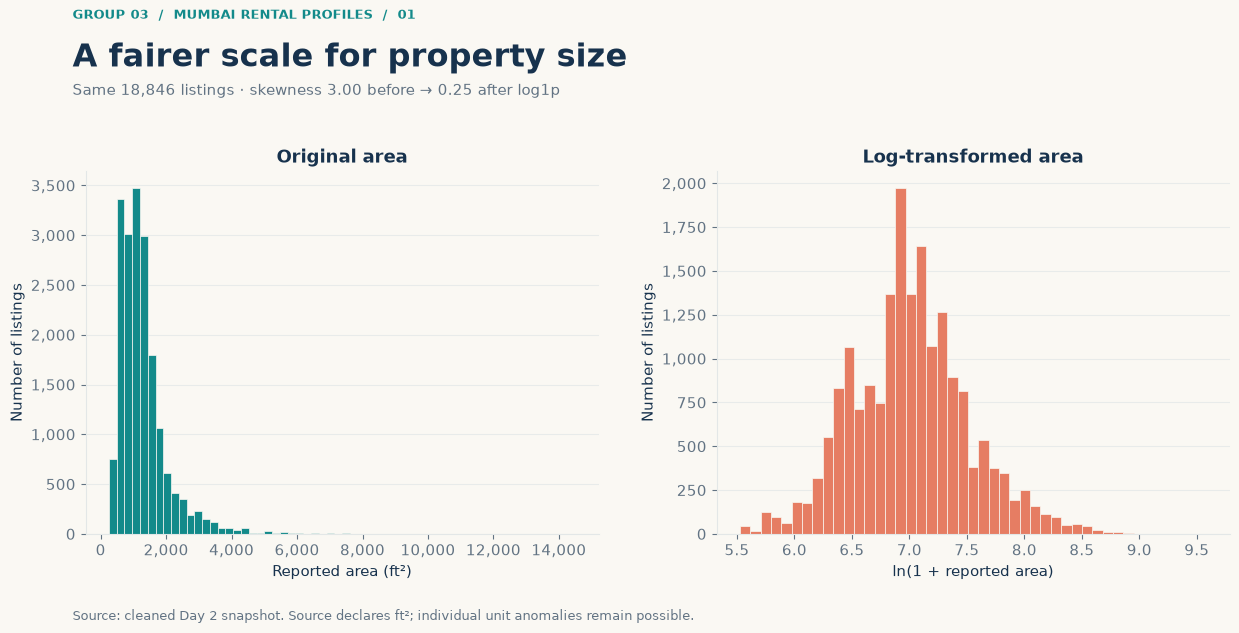

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.6))
fig.subplots_adjust(left=0.08, right=0.96, bottom=0.17, top=0.72, wspace=0.23)
area = X_cluster["Area_num"]
axes[0].hist(area, bins=60, color=TEAL, edgecolor=PAPER, linewidth=0.5)
axes[1].hist(np.log1p(area), bins=45, color=CORAL, edgecolor=PAPER, linewidth=0.5)
for ax in axes:
    ax.set_ylabel("Number of listings")
    ax.grid(axis="y")
    ax.set_axisbelow(True)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"{value:,.0f}"))
axes[0].set(xlabel="Reported area (ft²)", title="Original area")
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"{value:,.0f}"))
axes[1].set(xlabel="ln(1 + reported area)", title="Log-transformed area")
heading(fig, "01", "A fairer scale for property size",
        f"Same {len(area):,} listings · skewness {area.skew():.2f} before → {np.log1p(area).skew():.2f} after log1p",
        "Source: cleaned Day 2 snapshot. Source declares ft²; individual unit anomalies remain possible.")
save_figure(fig, "01_area_transformation")

### Figure 2 — PCA: Explained Variance

This figure shows the proportion of variance explained by each principal component (PC) and the cumulative variance explained by the components. PCA transforms the three original features, log-transformed property area, number of bedrooms, and number of bathrooms, into new axes that capture the main directions of variation in the dataset.

The first principal component (PC1) captures the largest proportion of variance, while PC2 captures the next largest proportion. Together, the first two components reportedly explain approximately **96.31% of the total variance**, allowing the dataset to be represented in two dimensions while retaining most of its variation.

**Key takeaway:** PCA helps reduce the dimensionality of the dataset while preserving most of the information represented by the variance in the original features.

In [21]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3, svd_solver="full")
pca_scores = pca.fit_transform(X_scaled)
variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(variance_ratio)
components_for_95 = int(np.searchsorted(cumulative_variance, 0.95) + 1)

pca_coordinates = pd.DataFrame({
    "source_row": analysis_data["source_row"].to_numpy(),
    "pca_x": pca_scores[:, 0],
    "pca_y": pca_scores[:, 1],
}, index=analysis_data.index)
assert len(pca_coordinates) == len(analysis_data)
assert np.isfinite(pca_scores).all()
np.testing.assert_allclose(variance_ratio.sum(), 1.0)

display(pd.DataFrame({
    "Component": ["PC1", "PC2", "PC3"],
    "Explained variance (%)": 100 * variance_ratio,
    "Cumulative variance (%)": 100 * cumulative_variance,
}).round(2))
print("Components needed for at least 95% variance:", components_for_95)
print("Coordinates are kept in memory; the final dataset has not been exported.")

,Component,Explained variance (%),Cumulative variance (%)
0,PC1,90.19,90.19
1,PC2,6.12,96.31
2,PC3,3.69,100.00


Components needed for at least 95% variance: 2
Coordinates are kept in memory; the final dataset has not been exported.


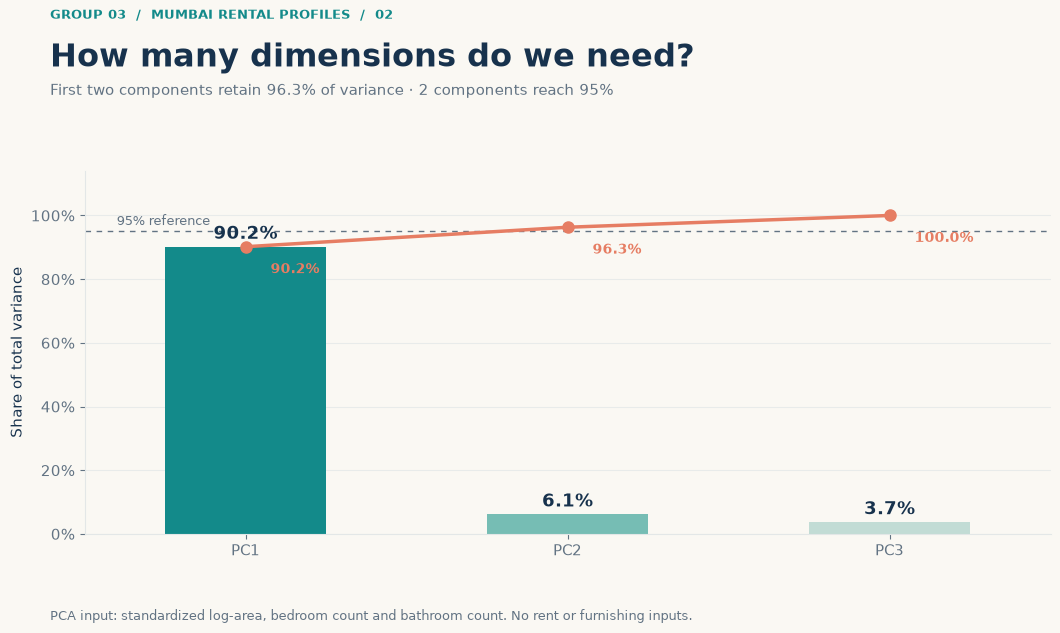

In [22]:
fig, ax = plt.subplots(figsize=(11.5, 6.6))
fig.subplots_adjust(left=0.10, right=0.94, bottom=0.17, top=0.72)
x = np.arange(1, 4)
ax.bar(x, variance_ratio, width=0.50, color=[TEAL, "#76BDB4", "#C2DCD5"], zorder=2)
ax.plot(x, cumulative_variance, color=CORAL, marker="o", markersize=8, linewidth=2.5, zorder=3)
ax.axhline(0.95, color=MUTED, linestyle=(0, (4, 4)), linewidth=1)
ax.text(0.60, 0.97, "95% reference", color=MUTED, fontsize=9)
for index, value in enumerate(variance_ratio, 1):
    ax.text(index, value + 0.025, f"{value:.1%}", ha="center", weight="bold", fontsize=13)
for index, value in enumerate(cumulative_variance, 1):
    ax.annotate(f"{value:.1%}", (index, value), xytext=(18, -19),
                textcoords="offset points", color=CORAL, fontsize=10, weight="bold")
ax.set(xlim=(0.5, 3.5), ylim=(0, 1.14), xticks=x, xticklabels=["PC1", "PC2", "PC3"],
       ylabel="Share of total variance")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="y")
ax.set_axisbelow(True)
heading(fig, "02", "How many dimensions do we need?",
        f"First two components retain {cumulative_variance[1]:.1%} of variance · {components_for_95} components reach 95%",
        "PCA input: standardized log-area, bedroom count and bathroom count. No rent or furnishing inputs.")
save_figure(fig, "02_pca_explained_variance")

### Figure 3 — PCA: Interpreting the Principal Components

This figure shows the coefficients (loadings) of the original features, log-transformed property area, number of bedrooms, and number of bathrooms, for the first two principal components (PC1 and PC2).

These coefficients indicate how each feature contributes to a principal component. Features with larger absolute coefficients have a stronger influence on that component, while the sign indicates the direction of the relationship.

By examining these loadings, we can better understand the patterns captured by PCA and interpret the new axes in terms of the original property characteristics.

**Key takeaway:** PCA loadings help explain which features contribute most to each principal component, making the reduced-dimensional representation easier to interpret.

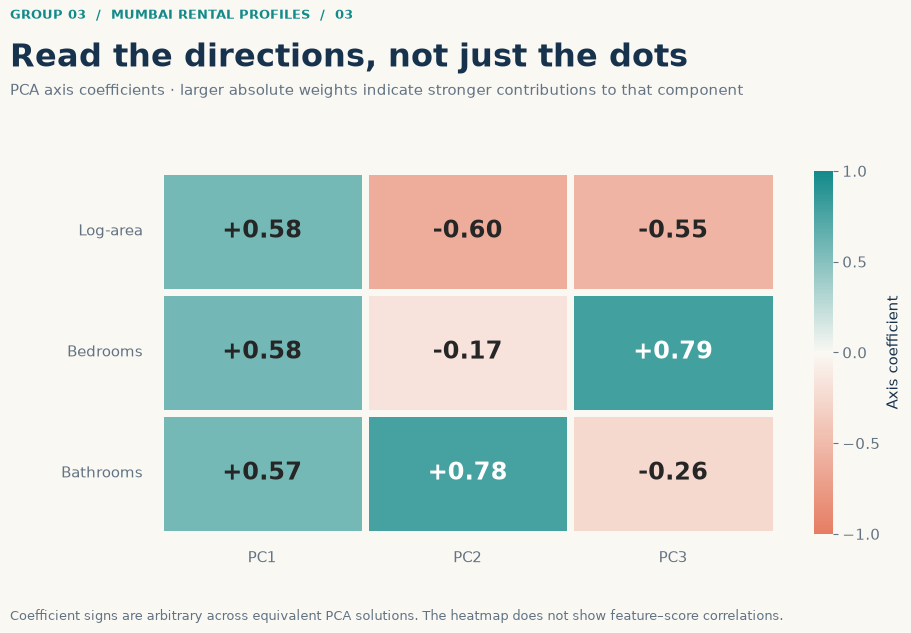

In [23]:
import seaborn as sns

axis_weights = pd.DataFrame(
    pca.components_.T,
    index=["Log-area", "Bedrooms", "Bathrooms"],
    columns=["PC1", "PC2", "PC3"],
)
fig, ax = plt.subplots(figsize=(11.5, 6.6))
fig.subplots_adjust(left=0.20, right=0.87, bottom=0.17, top=0.72)
weight_colors = LinearSegmentedColormap.from_list("axis_weights", [CORAL, PAPER, TEAL])
sns.heatmap(axis_weights, ax=ax, annot=True, fmt="+.2f", cmap=weight_colors,
            vmin=-1, vmax=1, center=0, linewidths=5, linecolor=PAPER,
            annot_kws={"size":17, "weight":"bold"},
            cbar_kws={"label":"Axis coefficient", "ticks":[-1, -0.5, 0, 0.5, 1]})
ax.tick_params(axis="both", length=0, pad=12)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
heading(fig, "03", "Read the directions, not just the dots",
        "PCA axis coefficients · larger absolute weights indicate stronger contributions to that component",
        "Coefficient signs are arbitrary across equivalent PCA solutions. The heatmap does not show feature–score correlations.")
save_figure(fig, "03_pca_axis_weights")

### Figure 4 — Visualising Physical Similarity and Rent

This figure represents the Mumbai rental listings in a two-dimensional PCA space using the first two principal components (PC1 and PC2). The left plot shows how the listings are distributed across the reduced-dimensional space, while the right plot colours the listings according to their median advertised monthly rent.

The visualisation helps us explore patterns in the dataset and investigate whether properties with similar physical characteristics tend to have similar rental prices. Areas with different colours may indicate variations in rent across the PCA space.

These plots are exploratory and do not establish that distinct clusters exist. Further analysis using clustering algorithms is required to identify and evaluate potential groups of similar properties.

**Key takeaway:** PCA provides a two-dimensional view of the rental listings, helping us explore relationships between property characteristics and rent before performing clustering.

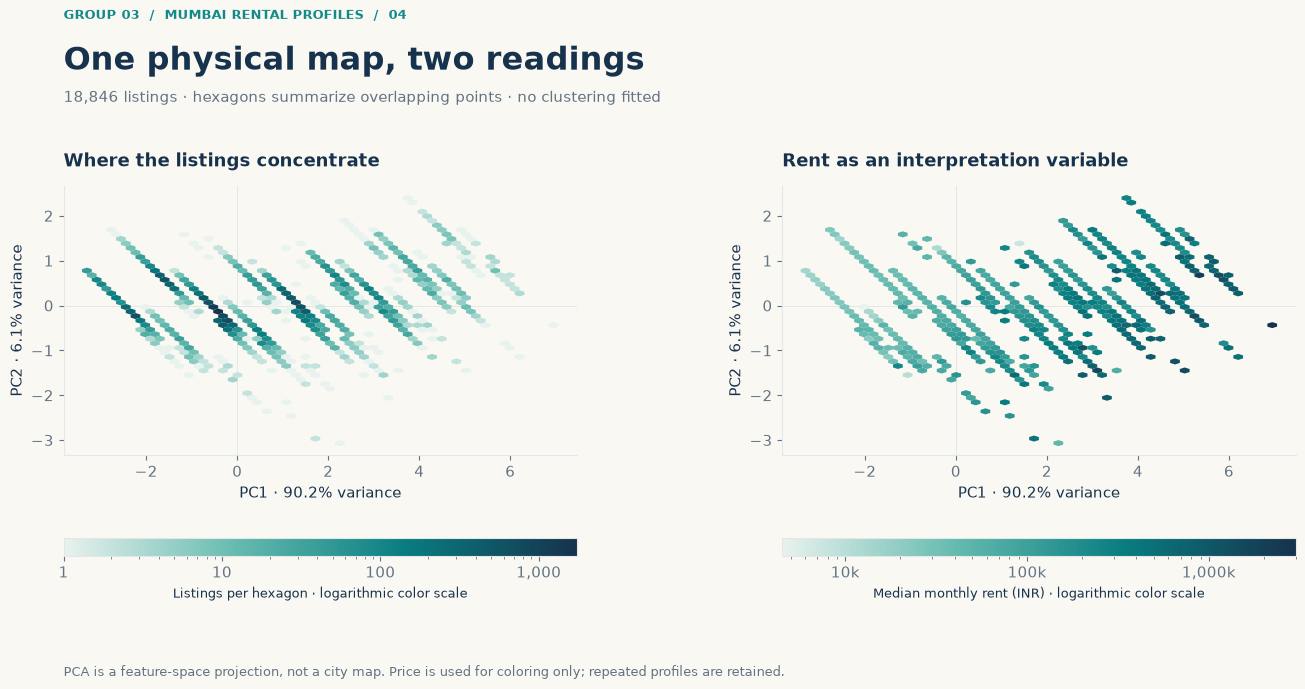

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7.2))
fig.subplots_adjust(left=0.07, right=0.95, bottom=0.20, top=0.72, wspace=0.40)
x_map, y_map = pca_scores[:, 0], pca_scores[:, 1]
density = axes[0].hexbin(x_map, y_map, gridsize=48, mincnt=1,
                         cmap=map_colors, norm=LogNorm(), linewidths=0)
rent_map = axes[1].hexbin(x_map, y_map,
    C=analysis_data["Price_num"].to_numpy(), reduce_C_function=np.median,
    gridsize=48, mincnt=1, cmap=map_colors, norm=LogNorm(), linewidths=0)
axes[0].set_title("Where the listings concentrate", loc="left", pad=14)
axes[1].set_title("Rent as an interpretation variable", loc="left", pad=14)
for ax in axes:
    ax.set_xlabel(f"PC1 · {variance_ratio[0]:.1%} variance")
    ax.set_ylabel(f"PC2 · {variance_ratio[1]:.1%} variance")
    ax.axhline(0, color=GRID, linewidth=0.7, zorder=0)
    ax.axvline(0, color=GRID, linewidth=0.7, zorder=0)
bar1 = fig.colorbar(density, ax=axes[0], orientation="horizontal", pad=0.22, fraction=0.06, aspect=28)
bar1.set_label("Listings per hexagon · logarithmic color scale", fontsize=9)
bar1.ax.xaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"{value:,.0f}"))
bar2 = fig.colorbar(rent_map, ax=axes[1], orientation="horizontal", pad=0.22, fraction=0.06, aspect=28)
bar2.set_label("Median monthly rent (INR) · logarithmic color scale", fontsize=9)
bar2.ax.xaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"{value/1000:,.0f}k"))
heading(fig, "04", "One physical map, two readings",
        f"{len(analysis_data):,} listings · hexagons summarize overlapping points · no clustering fitted",
        "PCA is a feature-space projection, not a city map. Price is used for coloring only; repeated profiles are retained.")
save_figure(fig, "04_pca_density_and_rent")


### Step 3 — Summary

In this step, we explored the Mumbai rental dataset through visualisations and Principal Component Analysis (PCA).

- **Log transformation:** Examined how transforming property area reduces the influence of very large values and helps us understand the feature's distribution.
- **Explained variance:** Evaluated how much variation each principal component captures. The first two components reportedly explain approximately 96.31% of the total variance.
- **PCA coefficients:** Investigated how property area, bedrooms, and bathrooms contribute to the principal components.
- **Visual exploration:** Represented the listings in two dimensions and explored how rental prices vary across the PCA space.

**Key takeaway:** PCA provides a lower-dimensional representation that preserves most of the variation in the prepared features. These visualisations help us understand the dataset before clustering, but they do not establish that distinct clusters exist.



## Step 4 — Compare clustering methods and select a working model

We cluster the **three prepared physical features**, not PCA or t-SNE map coordinates. Price and furnishing remain outside the clustering inputs.

We compare `k=2,...,8` for K-Means. Inertia always decreases with k, so it cannot select k alone. We inspect silhouette and the elbow and consider whether an extra group has an understandable physical profile. Silhouette is computed on the same reproducible 3,000-row subset for all full-data fits; it is a sample estimate, not a full-data score or supervised accuracy.

For a fair method comparison, K-Means and Ward hierarchical clustering are fitted on the **same 3,000-row reference sample**, using preprocessing fitted on that sample. Ward requires quadratic pairwise work, so we do not silently pretend it was fitted on all 18,846 rows. We compare silhouettes and adjusted Rand index (ARI) on the shared reference sample. Ward has no native predict; the final deployable model will be K-Means.

In [25]:
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, cut_tree, dendrogram
from threadpoolctl import threadpool_limits

reference_indices = np.sort(np.random.default_rng(42).choice(len(X_cluster), 3000, replace=False))
X_reference = clone(preprocessing).fit_transform(X_cluster.iloc[reference_indices])
comparison_rows = []
with threadpool_limits(limits=2):
    ward_linkage = linkage(X_reference, method="ward", metric="euclidean")
    for k in range(2, 9):
        candidate = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_scaled)
        reference_kmeans = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_reference)
        ward_labels = cut_tree(ward_linkage, n_clusters=k).ravel()
        comparison_rows.append({
            "k": k,
            "inertia_full": float(candidate.inertia_),
            "silhouette_sample": float(silhouette_score(X_scaled[reference_indices], candidate.labels_[reference_indices])),
            "reference_kmeans_silhouette": float(silhouette_score(X_reference, reference_kmeans.labels_)),
            "reference_ward_silhouette": float(silhouette_score(X_reference, ward_labels)),
            "methods_ari": float(adjusted_rand_score(reference_kmeans.labels_, ward_labels)),
            "smallest_cluster_share": float(np.bincount(candidate.labels_).min() / len(X_scaled)),
        })
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(5))


,k,inertia_full,silhouette_sample,reference_kmeans_silhouette,reference_ward_silhouette,methods_ari,smallest_cluster_share
0,2,21822.37587,0.56981,0.57057,0.56628,0.94047,0.35461
1,3,13521.76091,0.54975,0.55078,0.53956,0.85423,0.22541
2,4,8321.49650,0.57189,0.57308,0.56269,0.88347,0.08952
3,5,6962.90898,0.57928,0.58172,0.57317,0.88392,0.08941
4,6,6033.54426,0.56915,0.56882,0.54922,0.89451,0.03205
5,7,5266.97081,0.56874,0.57340,0.56515,0.92095,0.02780
6,8,4651.47263,0.50743,0.50972,0.51270,0.83779,0.03789


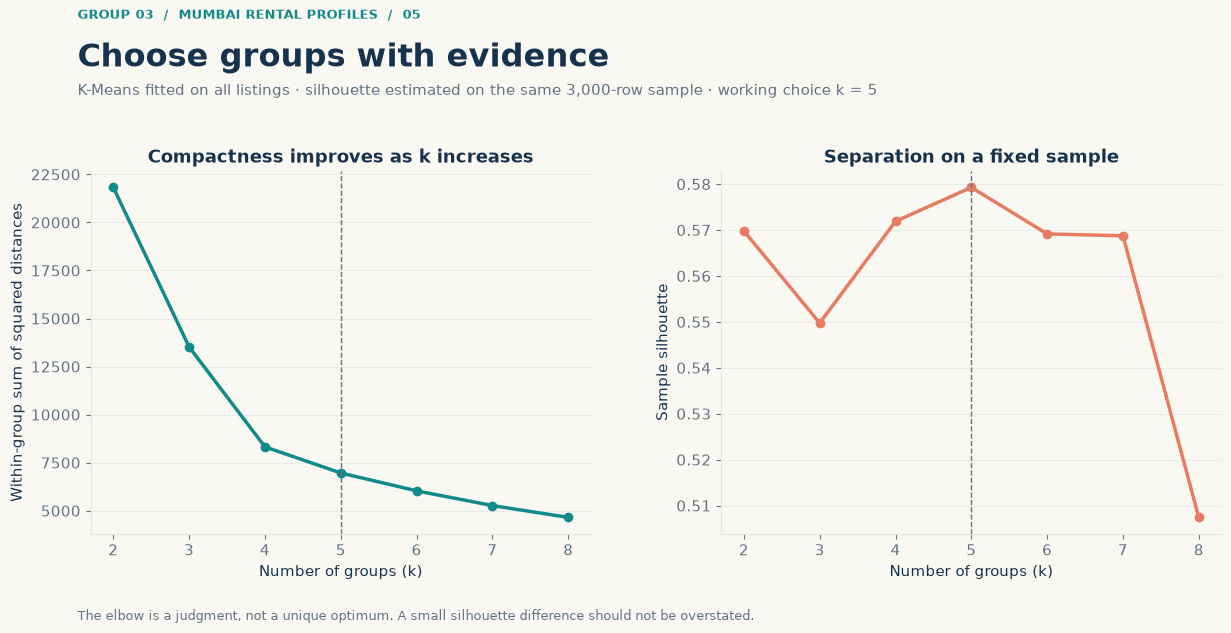

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.6))
fig.subplots_adjust(left=0.08, right=0.95, bottom=0.17, top=0.72, wspace=0.26)
axes[0].plot(comparison["k"], comparison["inertia_full"], color=TEAL, marker="o", linewidth=2.5)
axes[0].set(xlabel="Number of groups (k)", ylabel="Within-group sum of squared distances", title="Compactness improves as k increases")
axes[1].plot(comparison["k"], comparison["silhouette_sample"], color=CORAL, marker="o", linewidth=2.5)
axes[1].set(xlabel="Number of groups (k)", ylabel="Sample silhouette", title="Separation on a fixed sample")
for ax in axes:
    ax.set_xticks(comparison["k"])
    ax.axvline(5, color=MUTED, linestyle="--", linewidth=1)
    ax.grid(axis="y")
    ax.set_axisbelow(True)
heading(fig, "05", "Choose groups with evidence",
        "K-Means fitted on all listings · silhouette estimated on the same 3,000-row sample · working choice k = 5",
        "The elbow is a judgment, not a unique optimum. A small silhouette difference should not be overstated.")
save_figure(fig, "05_choice_of_k")

### Working choice: five physical profiles

The strongest inertia reductions occur before about k=4, while k=5 gives the highest sample silhouette in the tested range and separates compact one-bath and two-bath layouts. The difference from k=4 is small. We retain **k=5 as an interpretable working solution**, not a discovery of five objectively true housing types. Stability and profiles below are necessary checks.

K-Means is retained because its sample silhouette is slightly higher than Ward's at k=5, its groups are interpretable, and the complete fitted pipeline can assign new examples natively. This comparison concerns this sample and feature choice; it does not establish universal superiority.

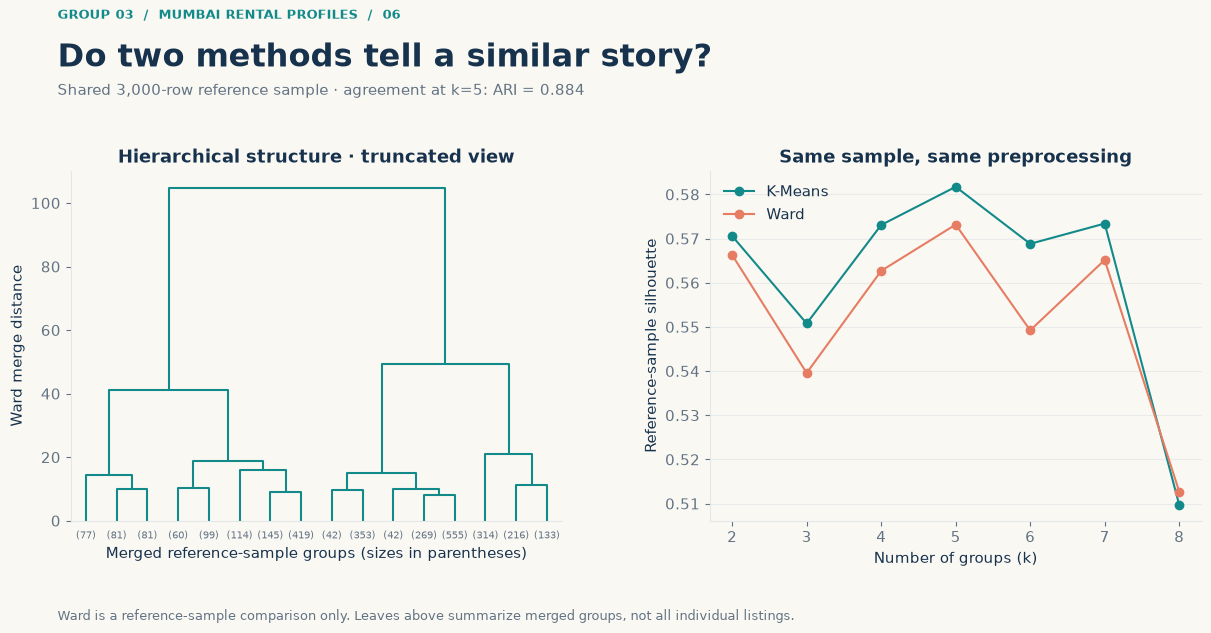

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.6))
fig.subplots_adjust(left=0.08, right=0.95, bottom=0.19, top=0.72, wspace=0.30)
dendrogram(ward_linkage, truncate_mode="lastp", p=16, ax=axes[0],
           color_threshold=0, above_threshold_color=TEAL, show_leaf_counts=True)
axes[0].set(xlabel="Merged reference-sample groups (sizes in parentheses)",
            ylabel="Ward merge distance", title="Hierarchical structure · truncated view")
axes[0].tick_params(axis="x", labelsize=7)
axes[1].plot(comparison["k"], comparison["reference_kmeans_silhouette"], color=TEAL, marker="o", label="K-Means")
axes[1].plot(comparison["k"], comparison["reference_ward_silhouette"], color=CORAL, marker="o", label="Ward")
axes[1].set(xlabel="Number of groups (k)", ylabel="Reference-sample silhouette", title="Same sample, same preprocessing")
axes[1].legend(frameon=False)
axes[1].set_xticks(comparison["k"])
axes[1].grid(axis="y")
selected_row = comparison.set_index("k").loc[5]
heading(fig, "06", "Do two methods tell a similar story?",
        f"Shared 3,000-row reference sample · agreement at k=5: ARI = {selected_row['methods_ari']:.3f}",
        "Ward is a reference-sample comparison only. Leaves above summarize merged groups, not all individual listings.")
save_figure(fig, "06_hierarchical_comparison")

In [28]:
SELECTED_K = 5
cluster_pipeline = Pipeline([
    ("preprocess", clone(preprocessing)),
    ("clusterer", KMeans(n_clusters=SELECTED_K, n_init=20, random_state=42)),
])
with threadpool_limits(limits=2):
    cluster_pipeline.fit(X_cluster)
cluster_labels = cluster_pipeline.predict(X_cluster)
np.testing.assert_array_equal(cluster_labels, cluster_pipeline.named_steps["clusterer"].labels_)
assert len(np.unique(cluster_labels)) == SELECTED_K
print("Final working model: full preprocessing + K-Means, k=5, n_init=20, seed=42")
print("Model fitted on", len(X_cluster), "listings; all three prepared physical features retained.")


Final working model: full preprocessing + K-Means, k=5, n_init=20, seed=42
Model fitted on 18846 listings; all three prepared physical features retained.


## Step 5 — Stability and repeated-profile sensitivity

ARI compares assignments without being affected by arbitrary cluster-number permutations: 1 means identical partitions; values near 0 indicate chance-level agreement under its adjustment. These checks are not prediction accuracy or confidence intervals.

We refit the complete pipeline for five seeds and for five random 80% subsamples. Subsample preprocessing is learned on the subsample only. We compare both full-sample assignments and the assignments of the excluded 20% against the reference partition. This is a sensitivity analysis, not evaluation against known true clusters.

We also fit a separate pipeline giving each distinct raw physical feature combination one training row, then assign the original sample. This changes weighting and fitted medians/scales. It tests dependence on repeated profiles; it does not identify or remove duplicate dwellings. The published working solution retains every eligible listing and the sensitivity result is reported separately.

In [29]:
stability_rows = []
seeds = [7, 21, 42, 84, 123]
with threadpool_limits(limits=2):
    for seed in seeds:
        seed_pipeline = clone(cluster_pipeline).set_params(clusterer__random_state=seed)
        seed_pipeline.fit(X_cluster)
        stability_rows.append({"check": "Different seed", "seed": seed,
            "ari_all": float(adjusted_rand_score(cluster_labels, seed_pipeline.predict(X_cluster))),
            "ari_excluded": np.nan})
        selected = np.sort(np.random.default_rng(seed).choice(len(X_cluster), int(0.8*len(X_cluster)), replace=False))
        excluded = np.setdiff1d(np.arange(len(X_cluster)), selected)
        sample_pipeline = clone(cluster_pipeline).set_params(clusterer__random_state=seed)
        sample_pipeline.fit(X_cluster.iloc[selected])
        sample_predictions = sample_pipeline.predict(X_cluster)
        stability_rows.append({"check": "80% subsample", "seed": seed,
            "ari_all": float(adjusted_rand_score(cluster_labels, sample_predictions)),
            "ari_excluded": float(adjusted_rand_score(cluster_labels[excluded], sample_predictions[excluded]))})
    unique_profiles = X_cluster.drop_duplicates()
    unique_pipeline = clone(cluster_pipeline).fit(unique_profiles)
    unique_weight_ari = float(adjusted_rand_score(cluster_labels, unique_pipeline.predict(X_cluster)))
stability = pd.DataFrame(stability_rows)
display(stability.round(5))
stability_summary = stability.groupby("check")["ari_all"].agg(["mean", "std", "min", "max"])
# Population SD across the five runs, matching our stated reporting convention.
stability_summary["std"] = stability.groupby("check")["ari_all"].std(ddof=0)
display(stability_summary.round(5))
print("Distinct physical profiles used for the weighting check:", len(unique_profiles))
print("Equal-profile-weighting ARI against the listing-weighted reference:", unique_weight_ari)


,check,seed,ari_all,ari_excluded
0,Different seed,7,0.99360,NaN
1,80% subsample,7,0.99927,0.99910
2,Different seed,21,0.99199,NaN
3,80% subsample,21,0.99266,0.99189
4,Different seed,42,1.00000,NaN
5,80% subsample,42,0.98882,0.98944
6,Different seed,84,0.99019,NaN
7,80% subsample,84,0.98887,0.99187
8,Different seed,123,0.98525,NaN
9,80% subsample,123,0.98543,0.97750


,mean,std,min,max
check,,,,
80% subsample,0.99101,0.00472,0.98543,0.99927
Different seed,0.99220,0.00480,0.98525,1.00000


Distinct physical profiles used for the weighting check: 2478
Equal-profile-weighting ARI against the listing-weighted reference: 0.8414894188661575


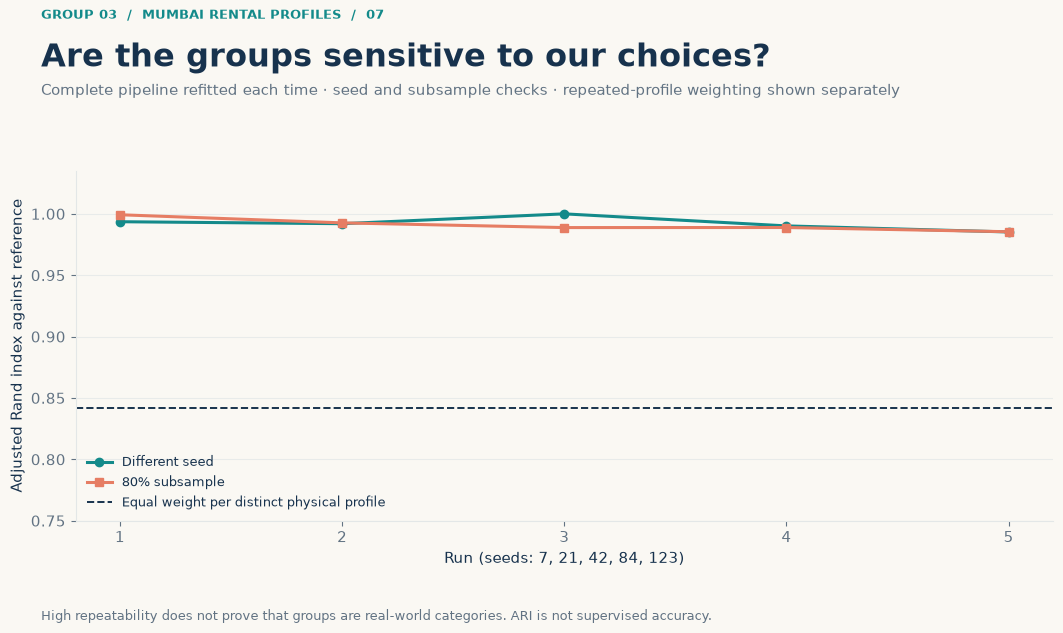

In [30]:
fig, ax = plt.subplots(figsize=(11.5, 6.6))
fig.subplots_adjust(left=0.10, right=0.95, bottom=0.19, top=0.72)
for label, color, marker in [("Different seed", TEAL, "o"), ("80% subsample", CORAL, "s")]:
    part = stability[stability["check"] == label]
    ax.plot(np.arange(1,6), part["ari_all"], color=color, marker=marker, linewidth=2.2, label=label)
ax.axhline(unique_weight_ari, color=NAVY, linestyle="--", linewidth=1.4, label="Equal weight per distinct physical profile")
ax.set(xlabel="Run (seeds: 7, 21, 42, 84, 123)", ylabel="Adjusted Rand index against reference",
       xticks=np.arange(1,6), ylim=(min(0.75, unique_weight_ari-0.05),1.035))
ax.legend(frameon=False, loc="lower left", fontsize=9)
ax.grid(axis="y")
heading(fig, "07", "Are the groups sensitive to our choices?",
        "Complete pipeline refitted each time · seed and subsample checks · repeated-profile weighting shown separately",
        "High repeatability does not prove that groups are real-world categories. ARI is not supervised accuracy.")
save_figure(fig, "07_cluster_stability")


## Step 6 — Profiles, interpretation variables and names

We describe each cluster with original-unit medians and size. Names are based on the physical profiles, **not on rent**, so they remain defensible without having used price in fitting. They describe typical profiles, not strict membership rules: a group's median bedroom count does not imply every member has that count.

Furnishing, property type and facing are cross-tabulated below because they were kept aside. Missing furnishing is a separate category rather than silently removed. City cannot distinguish clusters because Location is constant. Rent differences are associations in the listings, not performance predictions or causal effects.

In [31]:
profile_data = analysis_data.copy()
profile_data["cluster"] = cluster_labels
cluster_profiles = profile_data.groupby("cluster").agg(
    listings=("source_row", "size"), area_median=("Area_num", "median"),
    bedrooms_median=("BHK_num", "median"), bathrooms_median=("Bathrooms_num", "median"),
    rent_median=("Price_num", "median"), rent_q25=("Price_num", lambda x:x.quantile(.25)),
    rent_q75=("Price_num", lambda x:x.quantile(.75)),
)
cluster_profiles["share_percent"] = 100 * cluster_profiles["listings"] / len(profile_data)
display(cluster_profiles.round(2))

# Proposed names supported by the medians above, not claims that every member is identical.
CLUSTER_NAMES = {
    0: "Two-bedroom profiles",
    1: "Three-bedroom profiles",
    2: "Compact, one-bath profiles",
    3: "Large, multi-room profiles",
    4: "Compact, two-bath profiles",
}
# Verify that these descriptions still match the fitted partition before exporting.
expected_medians = {0:(2,2), 1:(3,3), 2:(1,1), 3:(4,4), 4:(1,2)}
for cluster_id, (bedrooms, bathrooms) in expected_medians.items():
    assert cluster_profiles.loc[cluster_id,"bedrooms_median"] == bedrooms
    assert cluster_profiles.loc[cluster_id,"bathrooms_median"] == bathrooms
profile_data["cluster_name"] = profile_data["cluster"].map(CLUSTER_NAMES)
cluster_profiles.insert(0,"cluster_name",cluster_profiles.index.map(CLUSTER_NAMES))

cross_tabs = {}
for column in ["Furnished_clean", "Property Type", "Facing"]:
    cross_tabs[column] = pd.crosstab(profile_data["cluster_name"], profile_data[column].fillna("Missing"), normalize="index")
    print("Within-cluster proportions:",column)
    display(cross_tabs[column].round(3))

,listings,area_median,bedrooms_median,bathrooms_median,rent_median,rent_q25,rent_q75,share_percent
cluster,,,,,,,,
0,8006,1025.0,2.0,2.0,65000.0,50000.0,85000.0,42.48
1,4870,1575.0,3.0,3.0,130000.0,88000.0,180000.0,25.84
2,2272,565.0,1.0,1.0,31000.0,20000.0,45000.0,12.06
3,1685,2750.0,4.0,4.0,300000.0,200000.0,450000.0,8.94
4,2013,650.0,1.0,2.0,38000.0,30000.0,48000.0,10.68


Within-cluster proportions: Furnished_clean


Furnished_clean,Furnished,Missing,Semi-Furnished,Unfurnished
cluster_name,,,,
"Compact, one-bath profiles",0.277,0.000,0.338,0.385
"Compact, two-bath profiles",0.260,0.001,0.377,0.362
"Large, multi-room profiles",0.281,0.000,0.555,0.164
Three-bedroom profiles,0.253,0.001,0.501,0.245
Two-bedroom profiles,0.258,0.001,0.419,0.322


Within-cluster proportions: Property Type


Property Type,Apartment,Builder Floor Apartment,Penthouse,Residential House,Service Apartment,Villa
cluster_name,,,,,,
"Compact, one-bath profiles",0.894,0.031,0.000,0.072,0.001,0.002
"Compact, two-bath profiles",0.973,0.001,0.000,0.026,0.000,0.000
"Large, multi-room profiles",0.970,0.001,0.007,0.007,0.000,0.015
Three-bedroom profiles,0.985,0.001,0.001,0.009,0.000,0.003
Two-bedroom profiles,0.982,0.003,0.000,0.013,0.000,0.001


Within-cluster proportions: Facing


Facing,East,North,North - East,North - West,South,South - East,South -West,Unknown,West
cluster_name,,,,,,,,,
"Compact, one-bath profiles",0.401,0.074,0.093,0.013,0.011,0.014,0.025,0.278,0.090
"Compact, two-bath profiles",0.581,0.066,0.121,0.017,0.012,0.006,0.017,0.112,0.068
"Large, multi-room profiles",0.389,0.059,0.167,0.024,0.014,0.045,0.100,0.082,0.119
Three-bedroom profiles,0.484,0.073,0.164,0.023,0.011,0.014,0.042,0.073,0.115
Two-bedroom profiles,0.537,0.070,0.142,0.020,0.011,0.008,0.028,0.090,0.093


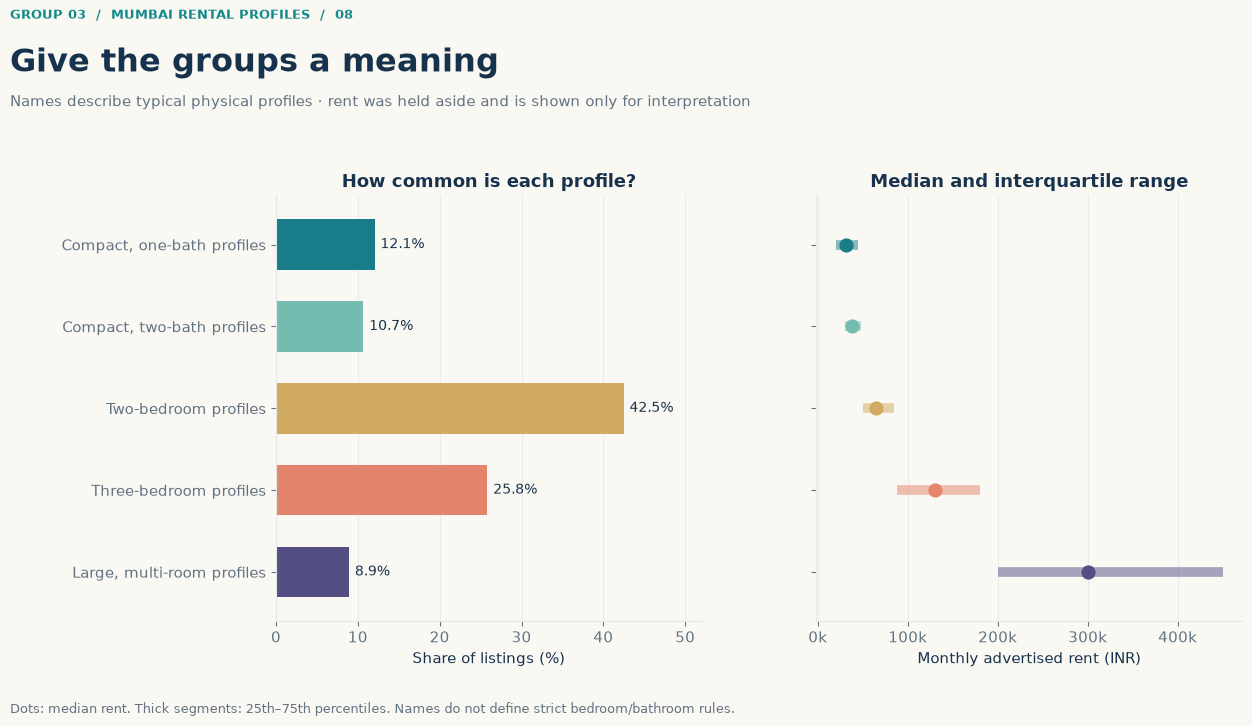

In [32]:
order = cluster_profiles.sort_values("area_median").index.tolist()
cluster_palette = {order[0]:"#187D88", order[1]:"#74BCAF", order[2]:"#D2AB62", order[3]:"#E5846C", order[4]:"#534F83"}
fig, axes = plt.subplots(1, 2, figsize=(14, 7.6))
fig.subplots_adjust(left=0.26, right=0.95, bottom=0.16, top=0.72, wspace=0.27)
positions = np.arange(SELECTED_K)
for row, cluster_id in enumerate(order):
    values = cluster_profiles.loc[cluster_id]
    axes[0].barh(row, values["share_percent"], color=cluster_palette[cluster_id], height=.62)
    axes[0].text(values["share_percent"]+.7,row,f"{values['share_percent']:.1f}%",va="center",fontsize=10)
    axes[1].hlines(row, values["rent_q25"], values["rent_q75"],color=cluster_palette[cluster_id],linewidth=7,alpha=.5)
    axes[1].scatter(values["rent_median"],row,s=85,color=cluster_palette[cluster_id],zorder=3)
axes[0].set(yticks=positions,yticklabels=[CLUSTER_NAMES[i] for i in order],xlabel="Share of listings (%)",xlim=(0,52),title="How common is each profile?")
axes[1].set(yticks=positions,yticklabels=[],xlabel="Monthly advertised rent (INR)",title="Median and interquartile range")
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda value,pos:f"{value/1000:.0f}k"))
for ax in axes:
    ax.set_ylim(-.6, SELECTED_K-.4)
    ax.invert_yaxis()
    ax.grid(axis="x")
    ax.set_axisbelow(True)
heading(fig,"08","Give the groups a meaning",
        "Names describe typical physical profiles · rent was held aside and is shown only for interpretation",
        "Dots: median rent. Thick segments: 25th–75th percentiles. Names do not define strict bedroom/bathroom rules.")
save_figure(fig,"08_cluster_profiles_and_rent")


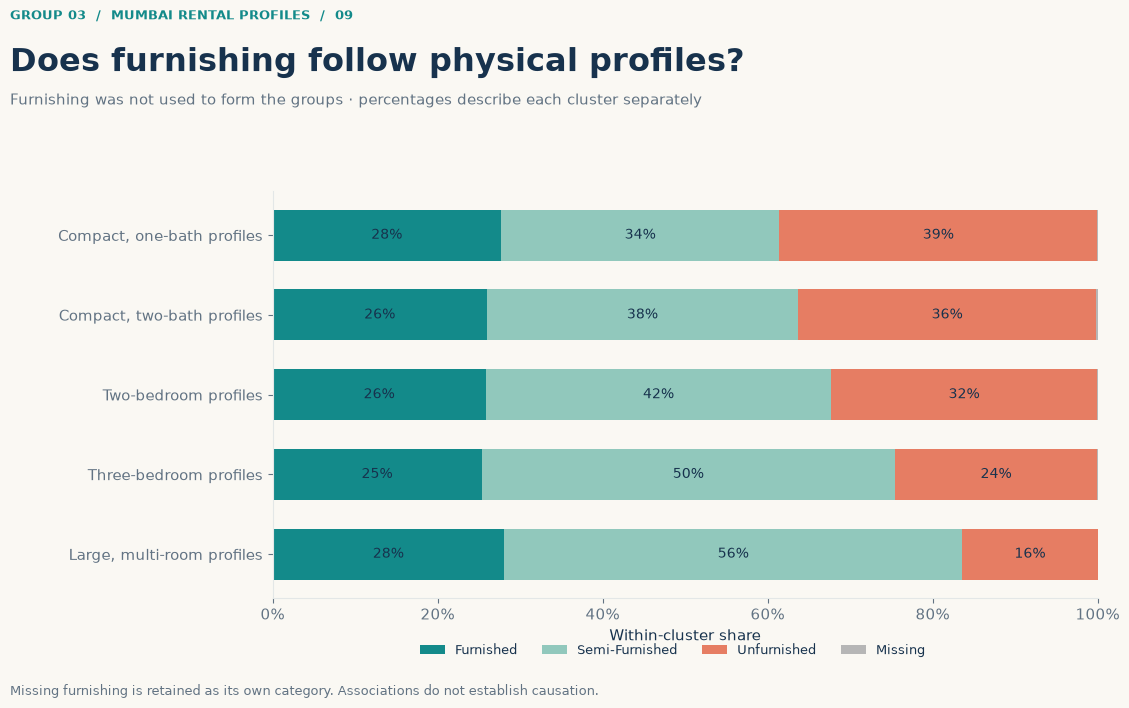

In [33]:
furnishing_table = pd.crosstab(profile_data["cluster"], profile_data["Furnished_clean"].fillna("Missing"),normalize="index").reindex(order)
fig, ax = plt.subplots(figsize=(12.5,7.4))
fig.subplots_adjust(left=.28,right=.94,bottom=.17,top=.72)
left = np.zeros(SELECTED_K)
furnishing_colors = {"Furnished":TEAL,"Semi-Furnished":"#91C8BC","Unfurnished":CORAL,"Missing":"#B6B6B6"}
for category in ["Furnished","Semi-Furnished","Unfurnished","Missing"]:
    if category not in furnishing_table:continue
    width = furnishing_table[category].to_numpy()
    ax.barh(np.arange(SELECTED_K),width,left=left,color=furnishing_colors[category],label=category,height=.64)
    for row,value in enumerate(width):
        if value>.08:ax.text(left[row]+value/2,row,f"{value:.0%}",ha="center",va="center",fontsize=10,color=NAVY)
    left += width
ax.set(yticks=np.arange(SELECTED_K),yticklabels=[CLUSTER_NAMES[i] for i in order],xlim=(0,1),xlabel="Within-cluster share")
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1))
fig.legend(loc="lower center",bbox_to_anchor=(.60,.075),ncol=4,frameon=False,fontsize=9)
heading(fig,"09","Does furnishing follow physical profiles?",
        "Furnishing was not used to form the groups · percentages describe each cluster separately",
        "Missing furnishing is retained as its own category. Associations do not establish causation.")
save_figure(fig,"09_furnishing_by_cluster")

## Step 7 — t-SNE as an additional map

The course asks for PCA **and** t-SNE or UMAP. We use t-SNE on the same three prepared features for all eligible rows, with two output dimensions, perplexity 40, PCA initialization, automatic learning rate, Barnes–Hut approximation, 1,000 iterations, seed 42 and two parallel neighbor-search jobs.

This map is **not** used to fit or select clusters. It is stochastic, and visual island sizes, distances between islands, and the orientation have no direct physical meaning. Repeated feature vectors and discrete room counts can make artificial-looking islands. The colors below show the already fitted K-Means groups; they are not groups discovered by t-SNE. A future new example receives a K-Means label; this fitted t-SNE map has no native transform for it.


In [34]:
from threadpoolctl import threadpool_limits
%pip install threadpoolctl

Note: you may need to restart the kernel to use updated packages.


In [35]:

import pandas as pd

# Show available DataFrame variables
for name, value in list(globals().items()):
    if isinstance(value, pd.DataFrame):
        print(f"{name}: {value.shape}")


_: (26, 2)
__: (26, 1)
___: (5, 26)
df: (18846, 26)
_11: (5, 26)
_12: (26, 1)
missing: (26, 2)
_13: (26, 2)
feature_audit: (3, 5)
working_data: (18846, 27)
analysis_data: (18846, 27)
X_cluster: (18846, 3)
scaled_features: (18846, 3)
example_property: (1, 3)
pca_coordinates: (18846, 3)
axis_weights: (3, 3)
comparison: (7, 7)
unique_profiles: (2478, 3)
stability: (10, 4)
stability_summary: (2, 4)
part: (5, 4)
profile_data: (18846, 29)
cluster_profiles: (5, 9)
furnishing_table: (5, 4)


In [36]:
from sklearn.manifold import TSNE
with threadpool_limits(limits=2):
    tsne = TSNE(n_components=2, perplexity=40, init="pca", learning_rate="auto",
                max_iter=1000, method="barnes_hut", angle=0.5, random_state=42, n_jobs=2)
    tsne_coordinates = tsne.fit_transform(X_scaled)
assert tsne_coordinates.shape == (len(analysis_data),2)
assert np.isfinite(tsne_coordinates).all()
print("t-SNE rows:",len(tsne_coordinates))
print("Final KL divergence:",float(tsne.kl_divergence_))
print("KL divergence is an embedding optimization diagnostic, not a cluster validity score.")


t-SNE rows: 18846
Final KL divergence: 0.16208511590957642
KL divergence is an embedding optimization diagnostic, not a cluster validity score.


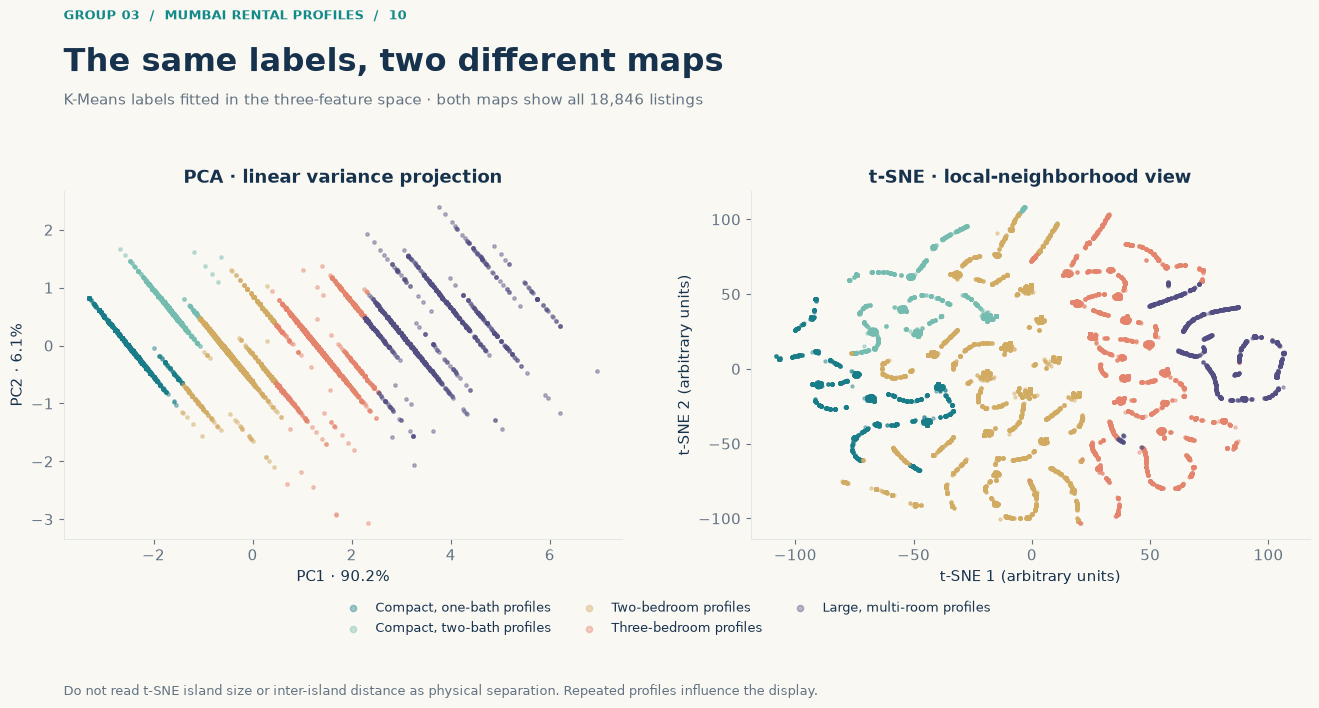

In [37]:
fig, axes = plt.subplots(1,2,figsize=(14,7.4))
fig.subplots_adjust(left=.07,right=.96,bottom=.25,top=.72,wspace=.23)
for cluster_id in order:
    mask = cluster_labels==cluster_id
    axes[0].scatter(pca_scores[mask,0],pca_scores[mask,1],s=6,alpha=.40,color=cluster_palette[cluster_id],rasterized=True)
    axes[1].scatter(tsne_coordinates[mask,0],tsne_coordinates[mask,1],s=5,alpha=.40,color=cluster_palette[cluster_id],label=CLUSTER_NAMES[cluster_id],rasterized=True)
axes[0].set(xlabel=f"PC1 · {variance_ratio[0]:.1%}",ylabel=f"PC2 · {variance_ratio[1]:.1%}",title="PCA · linear variance projection")
axes[1].set(xlabel="t-SNE 1 (arbitrary units)",ylabel="t-SNE 2 (arbitrary units)",title="t-SNE · local-neighborhood view")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles,labels,loc="lower center",bbox_to_anchor=(.5,.105),ncol=3,frameon=False,fontsize=9,markerscale=2)
heading(fig,"10","The same labels, two different maps",
        "K-Means labels fitted in the three-feature space · both maps show all 18,846 listings",
        "Do not read t-SNE island size or inter-island distance as physical separation. Repeated profiles influence the display.")
save_figure(fig,"10_pca_and_tsne_clusters")


# 7.1 Rent Gradients on t-SNE 
Instead of coloring each point by cluster, we color it by advertised monthly rent. This lets you investigate whether rental prices vary smoothly across physical profiles or whether similar properties have very different rents.

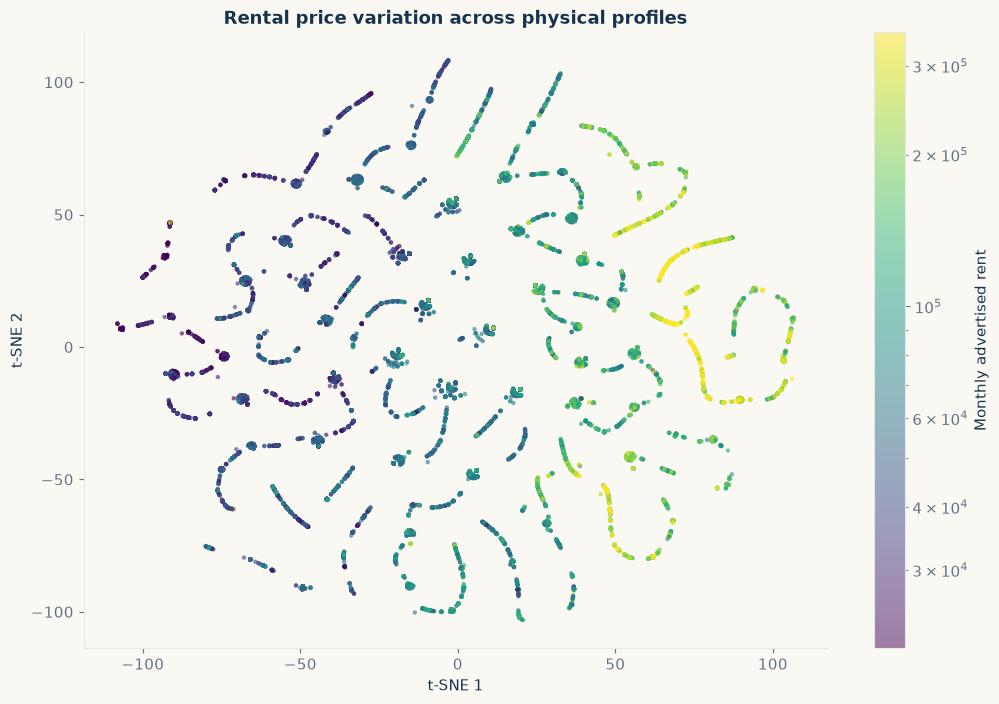

In [40]:

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

rent = analysis_data["Price_num"].to_numpy()
valid = np.isfinite(rent) & (rent > 0)

fig, ax = plt.subplots(figsize=(12, 8))

sc = ax.scatter(
    tsne_coordinates[valid, 0],
    tsne_coordinates[valid, 1],
    c=rent[valid],
    cmap="viridis",
    norm=LogNorm(
        vmin=np.percentile(rent[valid], 5),
        vmax=np.percentile(rent[valid], 95)
    ),
    s=5,
    alpha=0.5,
    rasterized=True
)

plt.colorbar(sc, ax=ax, label="Monthly advertised rent")
ax.set_title("Rental price variation across physical profiles")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
plt.show()


# 7.2 Cluster overlap and uncertainty
K-Means assigns every listing to a cluster, even when a listing sits close to two cluster centers. We can measure how ambiguous those assignments are using the distances to the nearest and second-nearest centroids.

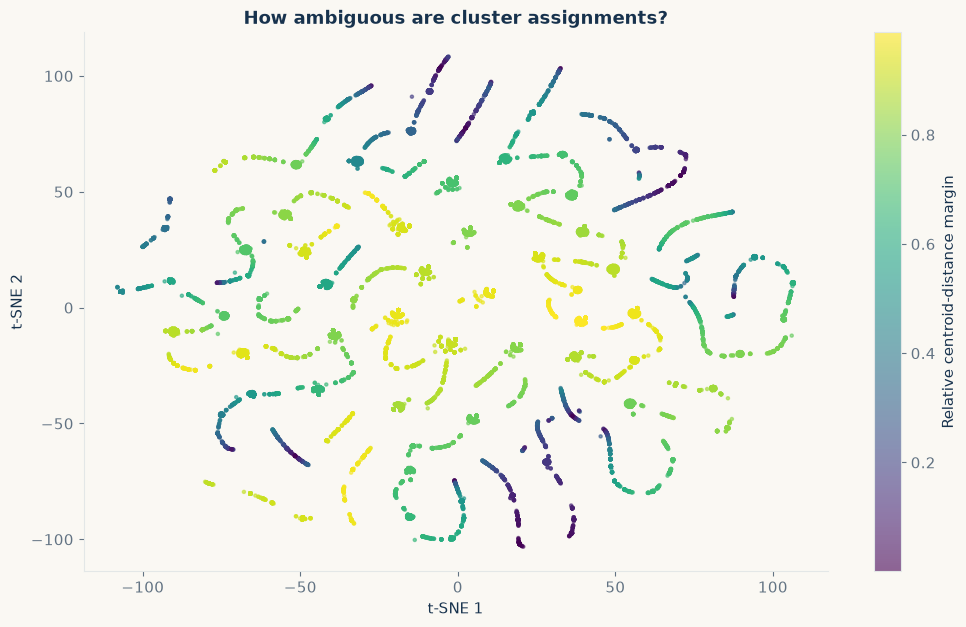

In [41]:

import numpy as np
import matplotlib.pyplot as plt

model = cluster_pipeline.named_steps["clusterer"]
prepared = cluster_pipeline.named_steps["preprocess"].transform(X_cluster)

distances = model.transform(prepared)
nearest = np.sort(distances, axis=1)

ambiguity = (
    (nearest[:, 1] - nearest[:, 0]) /
    np.maximum(nearest[:, 1], 1e-12)
)

fig, ax = plt.subplots(figsize=(12, 7))

sc = ax.scatter(
    tsne_coordinates[:, 0],
    tsne_coordinates[:, 1],
    c=ambiguity,
    cmap="viridis",
    s=5,
    alpha=0.6,
    rasterized=True
)

plt.colorbar(sc, label="Relative centroid-distance margin")
ax.set_title("How ambiguous are cluster assignments?")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
plt.show()


# 7.3 Rent per square foot across clusters
We already compared median rent by cluster. But larger apartments generally have higher total rents, so comparing rent relative to area can reveal another pattern.

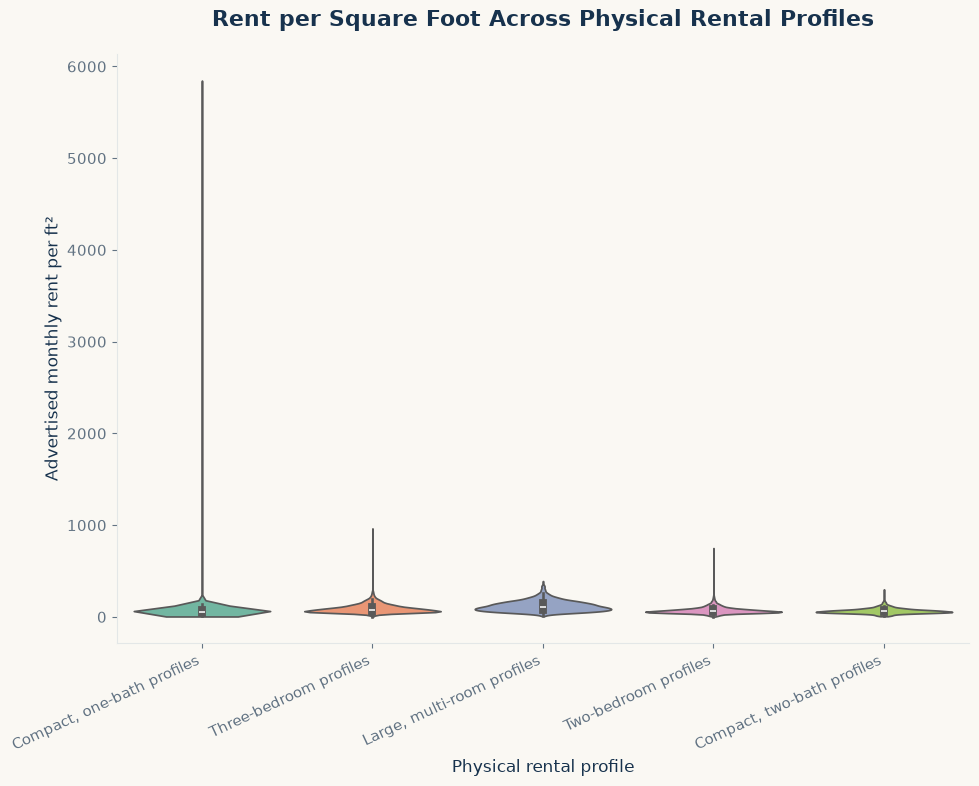

In [51]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(10,8))

sns.violinplot(
    data=rent_data,
    x="cluster_name",
    y="rent_per_sqft",
    hue="cluster_name",
    palette="Set2",
    inner="box",
    cut=0,
    density_norm="width",
    legend=False,
    ax=ax
)

ax.set_title(
    "Rent per Square Foot Across Physical Rental Profiles",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Physical rental profile", fontsize=12)
ax.set_ylabel("Advertised monthly rent per ft²", fontsize=12)

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


# 7.4 Does t-SNE actually preserve local neighbourhoods
We already warn that t-SNE maps can be misleading, but you can go further and quantify how faithfully PCA and t-SNE preserve local neighbors.Trustworthiness ranges from 0 to 1, with higher scores indicating fewer false neighbors in the embedding. This evaluates the displayed coordinates for the sampled rows; it does not establish that the clusters are valid.

In [43]:

from sklearn.manifold import trustworthiness
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
idx = rng.choice(
    len(X_scaled),
    size=min(2000, len(X_scaled)),
    replace=False
)

results = pd.DataFrame({
    "Method": ["PCA", "t-SNE"],
    "Trustworthiness": [
        trustworthiness(
            X_scaled[idx],
            pca_scores[idx, :2],
            n_neighbors=15
        ),
        trustworthiness(
            X_scaled[idx],
            tsne_coordinates[idx],
            n_neighbors=15
        )
    ]
})

display(results.round(4))


,Method,Trustworthiness
0,PCA,0.9951
1,t-SNE,0.9921


## Step 8 — Save locally, reload and assign a new example

The exported `models/model.joblib` contains the **entire fitted imputation, log-area, scaling and K-Means pipeline**. The only inputs are the original three numeric feature columns. The prediction is an arbitrary integer label; the separate cluster-name table explains it.

Joblib is pickle-based and can execute code when loaded. Here we reload a file just created by this notebook; do not load an unknown external pickle. Existing artifacts are preserved if a rerun produces different bytes: the new version is saved under a content-hash suffix for review. A matching export is reused.


In [38]:
import hashlib
import json
import joblib
from pathlib import Path

MODEL_DIR = project_dir / "models"
DATASET_DIR = project_dir / "dataset"
MODEL_DIR.mkdir(exist_ok=True)
DATASET_DIR.mkdir(exist_ok=True)

def save_reviewable_bytes(path, content):
    path = Path(path)
    if path.exists() and path.read_bytes() != content:
        digest = hashlib.sha256(content).hexdigest()[:12]
        path = path.with_name(f"{path.stem}-{digest}{path.suffix}")
    path.write_bytes(content)
    return path

import io
model_buffer = io.BytesIO()
joblib.dump(cluster_pipeline,model_buffer)
model_path = save_reviewable_bytes(MODEL_DIR / "model.joblib",model_buffer.getvalue())
loaded_cluster_pipeline = joblib.load(model_path)
np.testing.assert_array_equal(loaded_cluster_pipeline.predict(X_cluster),cluster_labels)
manual_example = pd.DataFrame([{"Area_num":750.0,"BHK_num":2.0,"Bathrooms_num":2.0}])
manual_cluster = int(loaded_cluster_pipeline.predict(manual_example)[0])
print("Saved model:", model_path.name)
print("Hand-made example cluster:",manual_cluster)
print("Hand-made example profile:",CLUSTER_NAMES[manual_cluster])
print("A label is a descriptive assignment, not a rental price or an eligibility decision.")


Saved model: model-a6abaac632e4.joblib
Hand-made example cluster: 0
Hand-made example profile: Two-bedroom profiles
A label is a descriptive assignment, not a rental price or an eligibility decision.


### Export the enriched table

The local output retains the cleaned columns needed to reproduce and interpret this analysis, plus engineered features, cluster labels/names and both 2D maps. It deliberately excludes titles, descriptions and image links, and does not pretend to include every original source column. `source_row` links each output row to the pinned cleaned CSV.

Missing raw bathrooms and furnishing remain visible. `bathrooms_imputed` and `bathroom_was_missing` document the processing. Standardized columns are dimensionless; log-area is ln(1 + reported ft²). Coordinates are for display, not geographic coordinates. No upload is performed.


In [39]:
enriched = analysis_data[["source_row","Area_num","BHK_num","Bathrooms_num","Balconies_num",
                          "Price_num","Furnished_clean","Facing","Location","Property Type"]].copy()
enriched["log_area"] = np.log1p(enriched["Area_num"])
bathroom_median = float(cluster_pipeline.named_steps["preprocess"].named_steps["features"].named_transformers_["counts"].named_steps["imputer"].statistics_[1])
enriched["bathrooms_imputed"] = enriched["Bathrooms_num"].fillna(bathroom_median)
enriched["bathroom_was_missing"] = enriched["Bathrooms_num"].isna()
for index,column in enumerate(["log_area_scaled","bhk_scaled","bathrooms_scaled"]):
    enriched[column] = X_scaled[:,index]
enriched["cluster"] = cluster_labels
enriched["cluster_name"] = enriched["cluster"].map(CLUSTER_NAMES)
enriched["pca_x"],enriched["pca_y"] = pca_scores[:,0],pca_scores[:,1]
enriched["tsne_x"],enriched["tsne_y"] = tsne_coordinates[:,0],tsne_coordinates[:,1]
assert len(enriched)==len(df)
assert enriched["source_row"].is_unique
assert enriched["cluster_name"].notna().all()
dataset_bytes = enriched.to_csv(index=False).encode("utf-8")
dataset_path = save_reviewable_bytes(DATASET_DIR / "mumbai_rental_profiles.csv",dataset_bytes)
reloaded_dataset = pd.read_csv(dataset_path)
np.testing.assert_array_equal(loaded_cluster_pipeline.predict(reloaded_dataset[cluster_features]),reloaded_dataset["cluster"])
names_bytes = (json.dumps(CLUSTER_NAMES,indent=2)+"\n").encode("utf-8")
names_path = save_reviewable_bytes(MODEL_DIR / "cluster_names.json",names_bytes)
profiles_path = save_reviewable_bytes(DATASET_DIR / "cluster_profiles.csv",cluster_profiles.to_csv().encode("utf-8"))
print("Exported rows and columns:",enriched.shape)
print("Dataset file:",dataset_path.name)
print("Reloaded labels match the pipeline for every row.")
display(cluster_profiles.round(2))


Exported rows and columns: (18846, 22)
Dataset file: mumbai_rental_profiles-5945ca9f81ac.csv
Reloaded labels match the pipeline for every row.


,cluster_name,listings,area_median,bedrooms_median,bathrooms_median,rent_median,rent_q25,rent_q75,share_percent
cluster,,,,,,,,,
0,Two-bedroom profiles,8006,1025.0,2.0,2.0,65000.0,50000.0,85000.0,42.48
1,Three-bedroom profiles,4870,1575.0,3.0,3.0,130000.0,88000.0,180000.0,25.84
2,"Compact, one-bath profiles",2272,565.0,1.0,1.0,31000.0,20000.0,45000.0,12.06
3,"Large, multi-room profiles",1685,2750.0,4.0,4.0,300000.0,200000.0,450000.0,8.94
4,"Compact, two-bath profiles",2013,650.0,1.0,2.0,38000.0,30000.0,48000.0,10.68


## Conclusion and group review

- Five working physical profiles summarize 18,846 listings. K-Means uses standardized log-area, bedrooms and bathrooms; rent and furnishing are interpretation variables.
- Among k=2 through 8, k=5 has the highest fixed-sample silhouette (0.579283), only slightly above k=4 (0.571893). The elbow is around four to five; this is not proof of a unique natural number of groups.
- Ward and K-Means agree substantially on the same 3,000-listing reference subset (ARI 0.883921 at k=5). Ward was not fitted to the full dataset.
- Mean ARI is 0.992204 across five seeds and 0.991012 across five 80% subsamples. These measure reproducibility, not accuracy. Giving each distinct raw physical tuple equal weight lowers agreement to 0.841489, so repeated profiles affect the result.
- The first two PCA axes explain 96.31% of variance. t-SNE supplies an additional local-neighborhood view; its islands and distances do not establish real housing-market segments.
- Larger physical profiles have higher median advertised rents in this snapshot. Location is only a city label, collection date is unknown, and unit consistency cannot be verified per listing. We cannot make neighborhood, causal, fair-housing or current market claims.

The fitted pipeline was saved and reloaded successfully, and its predictions reproduce all exported labels. A handmade 750-area, two-bedroom, two-bath input receives cluster 0, Two-bedroom profiles. Review feature weighting, names and limitations with the group before any submission or publication.
